In [8]:
import numpy
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import pandas as pd
import glob 
import os
import pickle


## find the file - time index

because all the data in 10 years are stored in different files, in a total of 30GB.


In [5]:
tab_files=glob.glob('data/_cassini-mag-cal (1)/*.TAB')
len(tab_files)

294

In [ ]:
file_name_list=[]
start_time_list=[]
end_time_list=[]

for tab_file in tab_files:
    # columns TIME,BR,BTHETA,BPHI,BTOTAL,NPTS
    temp_df=pd.read_csv(tab_file,delimiter='\s+',names=['TIME','BR','BTHETA','BPHI','BTOTAL','NPTS'])
    
    start_time=temp_df['TIME'].iloc[0]
    end_time=temp_df['TIME'].iloc[-1]
    
    # verify if the start time is the minimum of temp_df['TIME'], and end time is the latest of temp_df
    try: 
        assert start_time==temp_df['TIME'].min()
        assert end_time==temp_df['TIME'].max()
    except:
        # raise error
        raise ValueError(f"Error in file {tab_file}: start_time or end_time mismatch")
    
    file_name_list.append(tab_file)
    start_time_list.append(start_time)
    end_time_list.append(end_time)

index_df=pd.DataFrame({'file_name':file_name_list,
                          'start_time':start_time_list,
                            'end_time':end_time_list})
index_df['start_time','end_time']=index_df['start_time','end_time'].apply(pd.to_datetime)


<>:7: SyntaxWarning:

invalid escape sequence '\s'

<>:7: SyntaxWarning:

invalid escape sequence '\s'

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_93409/960015243.py:7: SyntaxWarning:

invalid escape sequence '\s'



In [16]:
index_df[['start_time','end_time']]=index_df[['start_time','end_time']].apply(pd.to_datetime)

In [18]:
with open('data/file_time_index.csv','wb') as f:
    pickle.dump(index_df,f)

## a function to select files

In [ ]:
start_time=pd.to_datetime('2010-12-21 02:00:00')
end_time=pd.to_datetime('2010-12-21 04:00:00')

In [51]:
def select_df(start_time,end_time):
    
    '''select files that cover the time range from start_time to end_time
    input: start_time, end_time - string or pd.Timestamp
    output: selected_files - pd.DataFrame with columns file_name, start_time, end_time
            '''
            
            
    with open('data/file_time_index.csv','rb') as f:
        index_df=pickle.load(f)
    
    start_time=pd.to_datetime(start_time)
    end_time=pd.to_datetime(end_time)
    
    # select files that cover the time range
    index_mask=(index_df['start_time']<=start_time) & (index_df['end_time']>=end_time)
    selected_index_df=index_df[index_mask]
    
    df=pd.DataFrame()
    for file in selected_index_df['file_name']:
        temp_df=pd.read_csv(file,delimiter='\s+',names=['TIME','BR','BTHETA','BPHI','BTOTAL','NPTS'])
        df=pd.concat([df,temp_df],ignore_index=True)
        
    df['TIME']=pd.to_datetime(df['TIME'])
    mask=(df['TIME']>=start_time) & (df['TIME']<=end_time)
    df=df.loc[mask].reset_index(drop=True)
    
    return df

<>:21: SyntaxWarning:

invalid escape sequence '\s'

<>:21: SyntaxWarning:

invalid escape sequence '\s'

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_93409/295396224.py:21: SyntaxWarning:

invalid escape sequence '\s'



In [52]:
df=select_df(start_time,end_time)

### detrend the data

In [62]:
def detrend_data(df):
    '''detrend the data by removing the linear trend'''
    df.set_index('TIME',inplace=True)
    df=df-df.rolling(window=1200,center=True).mean()   # 20 minutes window
    df.reset_index(inplace=True)
    return df


## Plotting

In [63]:
start_time=pd.to_datetime('2010-12-21 02:00:00')
end_time=pd.to_datetime('2010-12-21 04:00:00')

df=select_df(start_time,end_time)
df=detrend_data(df)

In [69]:
fig=make_subplots(rows=4,cols=1,shared_xaxes=True, vertical_spacing=0.02)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BR'],mode='lines',name='BR'),row=1,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTHETA'],mode='lines',name='BTHETA'),row=2,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BPHI'],mode='lines',name='BPHI'),row=3,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['BTOTAL'],mode='lines',name='BTOTAL'),row=4,col=1)

fig.update_xaxes(title_text="Time",row=4,col=1)
fig.update_yaxes(title_text="BR (nT)",row=1,col=1)
fig.update_yaxes(title_text="BTHETA (nT)",row=2,col=1)
fig.update_yaxes(title_text="BPHI (nT)",row=3,col=1)
fig.update_yaxes(title_text="BTOTAL (nT)",row=4,col=1)


fig.update_layout(height=800,title_text="Magnetic Field Components over Time")
fig.show()

## wavelet transform

In [70]:
from do_wavelet import do_wavelet

In [106]:
start_time=pd.to_datetime('2010-12-21 02:00:00')
end_time=pd.to_datetime('2010-12-22 04:00:00')

df=select_df(start_time,end_time)
df=detrend_data(df)

In [107]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS
0,2010-12-21 02:00:00.500,NaN,NaN,NaN,NaN,NaN
1,2010-12-21 02:00:01.500,NaN,NaN,NaN,NaN,NaN
2,2010-12-21 02:00:02.500,NaN,NaN,NaN,NaN,NaN
3,2010-12-21 02:00:03.500,NaN,NaN,NaN,NaN,NaN
4,2010-12-21 02:00:04.500,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
93388,2010-12-22 03:59:55.500,NaN,NaN,NaN,NaN,NaN
93389,2010-12-22 03:59:56.500,NaN,NaN,NaN,NaN,NaN
93390,2010-12-22 03:59:57.500,NaN,NaN,NaN,NaN,NaN
93391,2010-12-22 03:59:58.500,NaN,NaN,NaN,NaN,NaN


Data variance =  0.08460816516510843


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



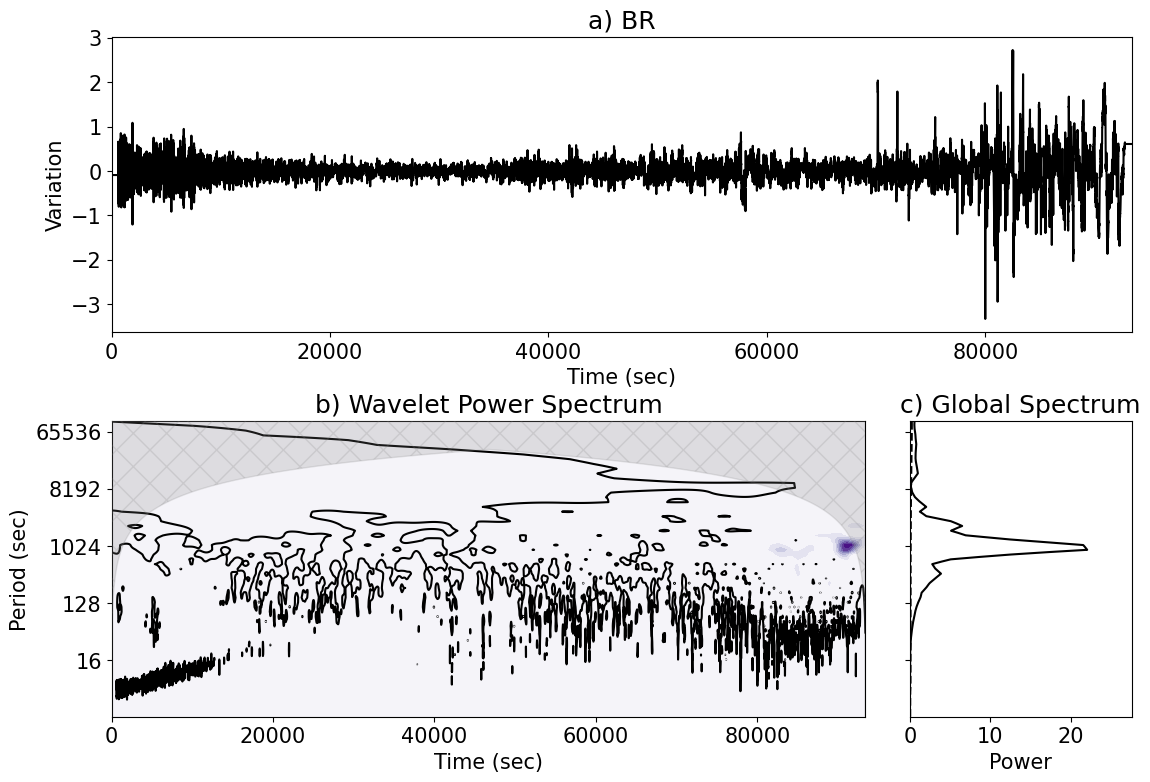

Data variance =  0.17547952000894934


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



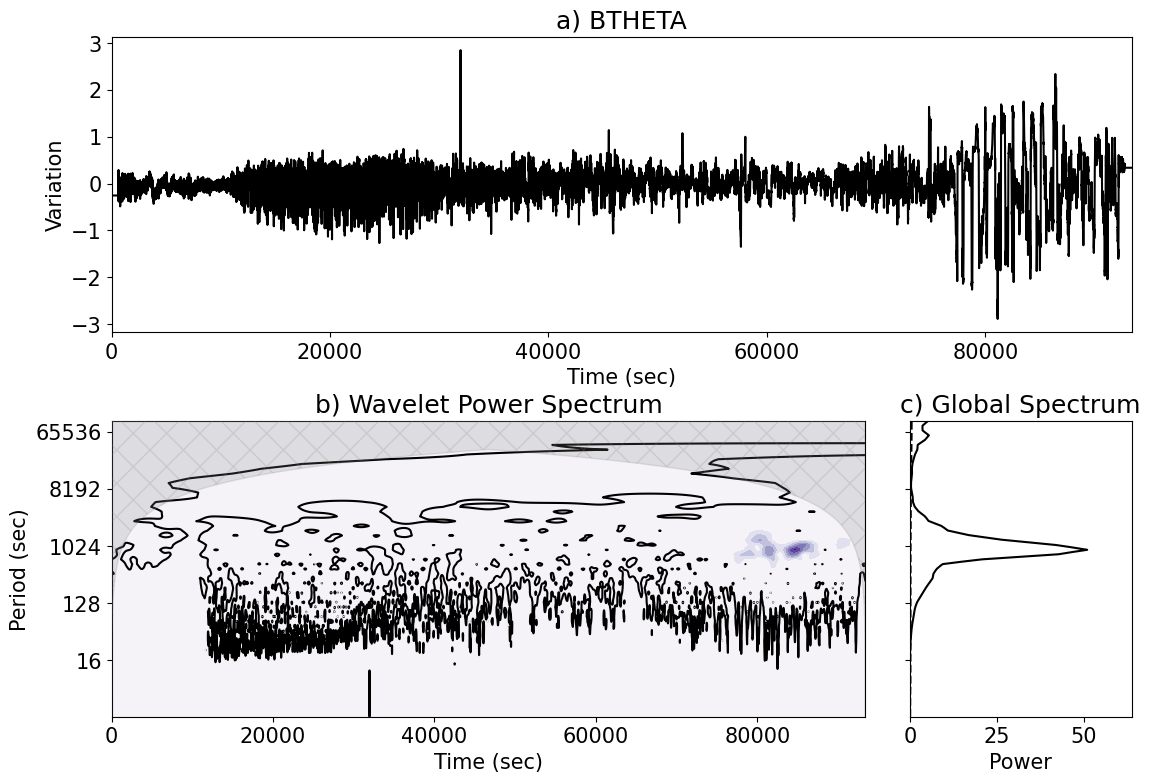

Data variance =  0.04749303475276382


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



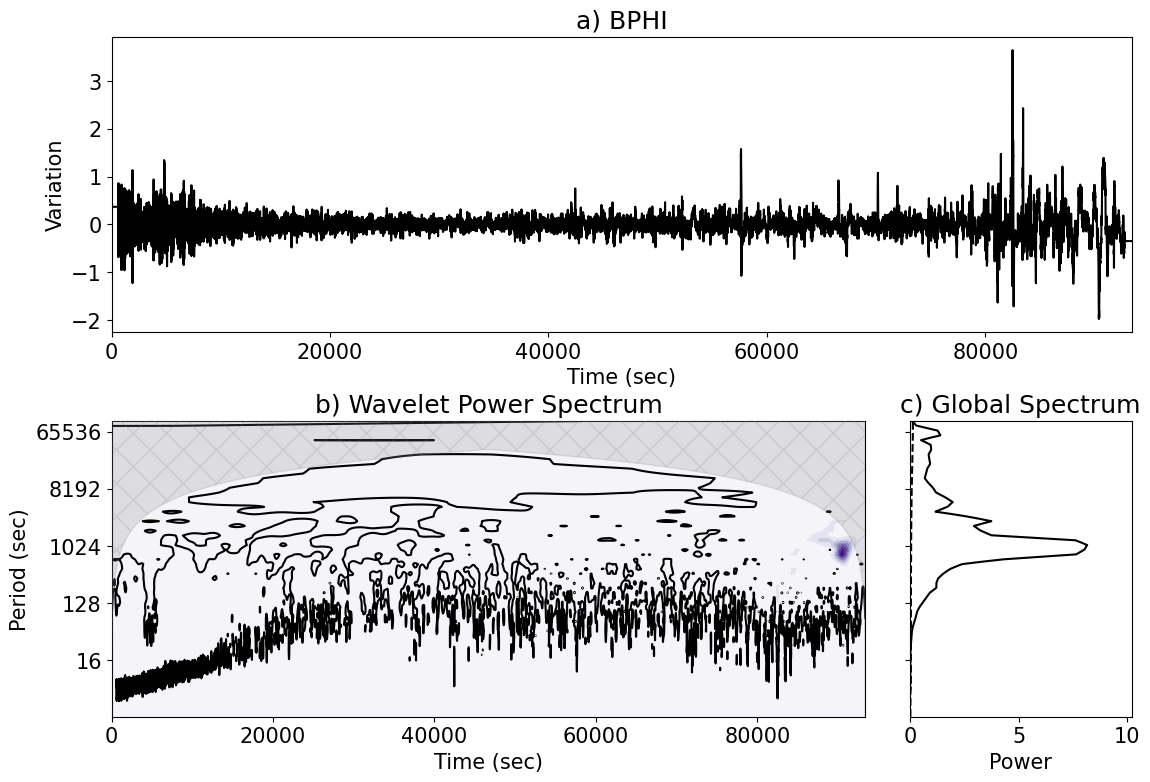

Data variance =  0.16639313991782034


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



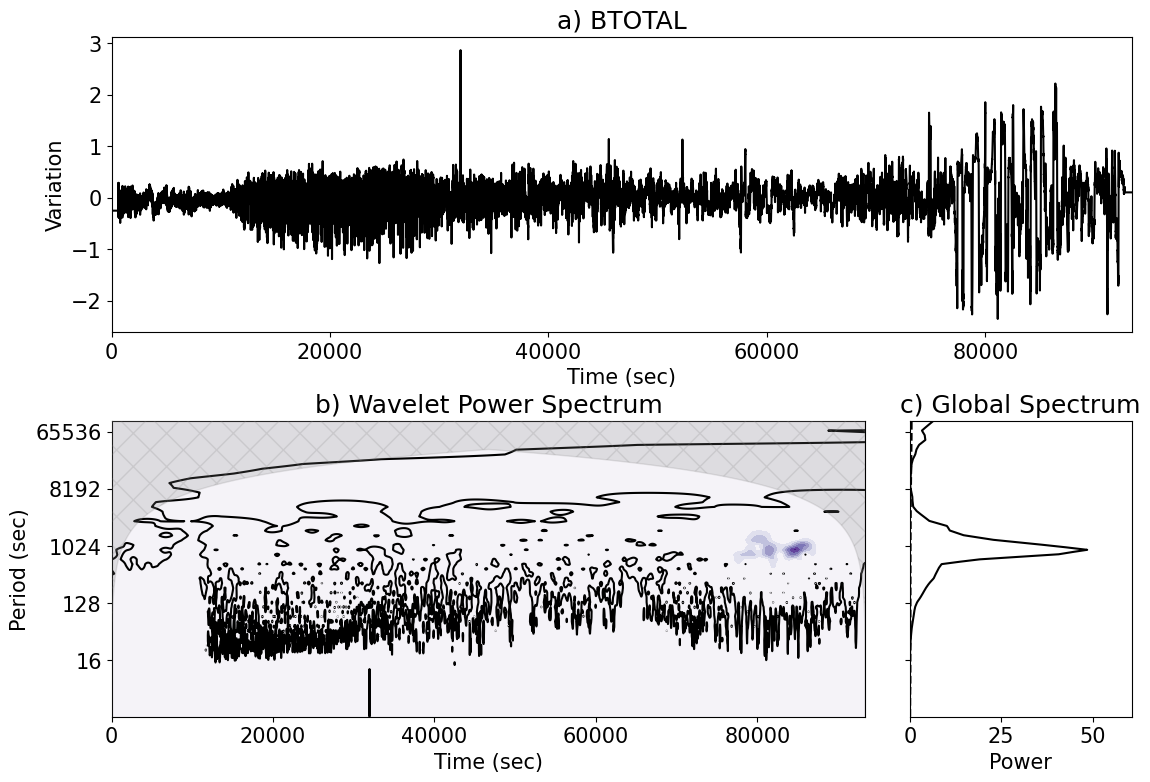

([np.float64(889.4660872954993), np.float64(47872.26608729554)],
 array([   29.6660873, 17799.8660873]),
 array([ 7729.8660873, 67701.4660873]))

In [108]:
do_wavelet(df['BR'].values[:-1],
           dt=1,unit='sec',title='BR')
do_wavelet(df['BTHETA'].values[:-1],
           dt=1,unit='sec',title='BTHETA')
do_wavelet(df['BPHI'].values[:-1],
           dt=1,unit='sec',title='BPHI')
do_wavelet(df['BTOTAL'].values[:-1],
           dt=1,unit='sec',title='BTOTAL')

Data variance =  0.06849338549192728


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



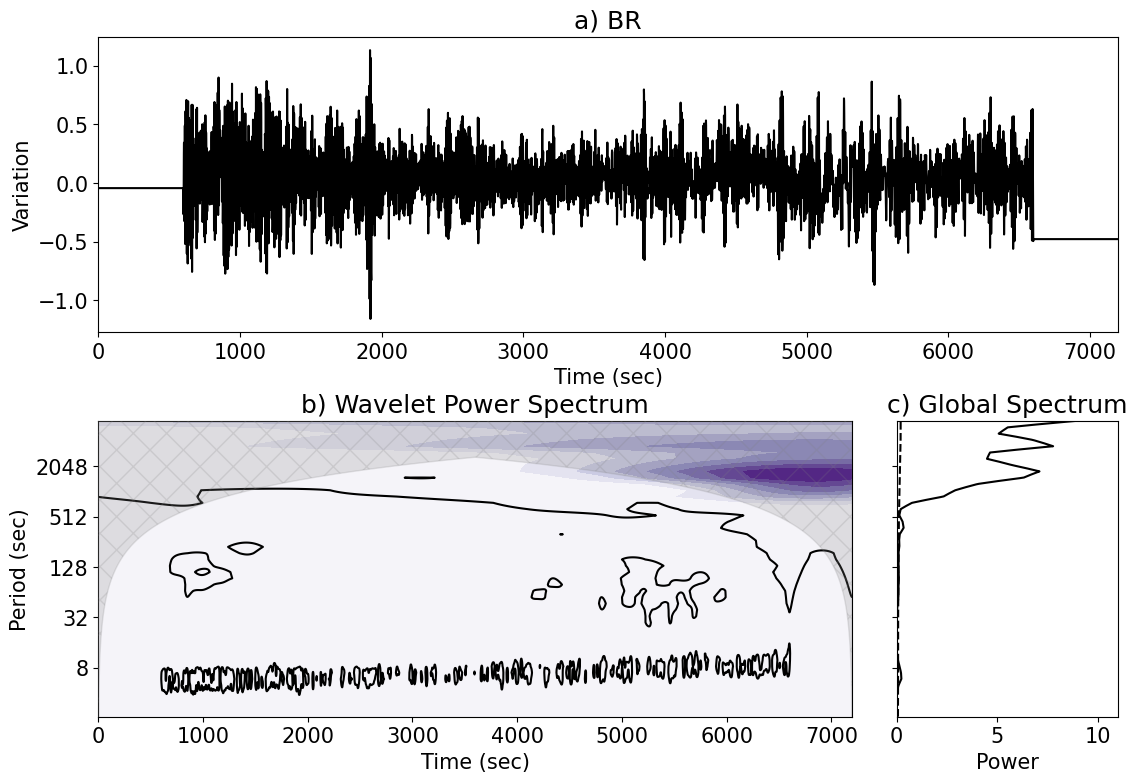

Data variance =  0.012394514833110352


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



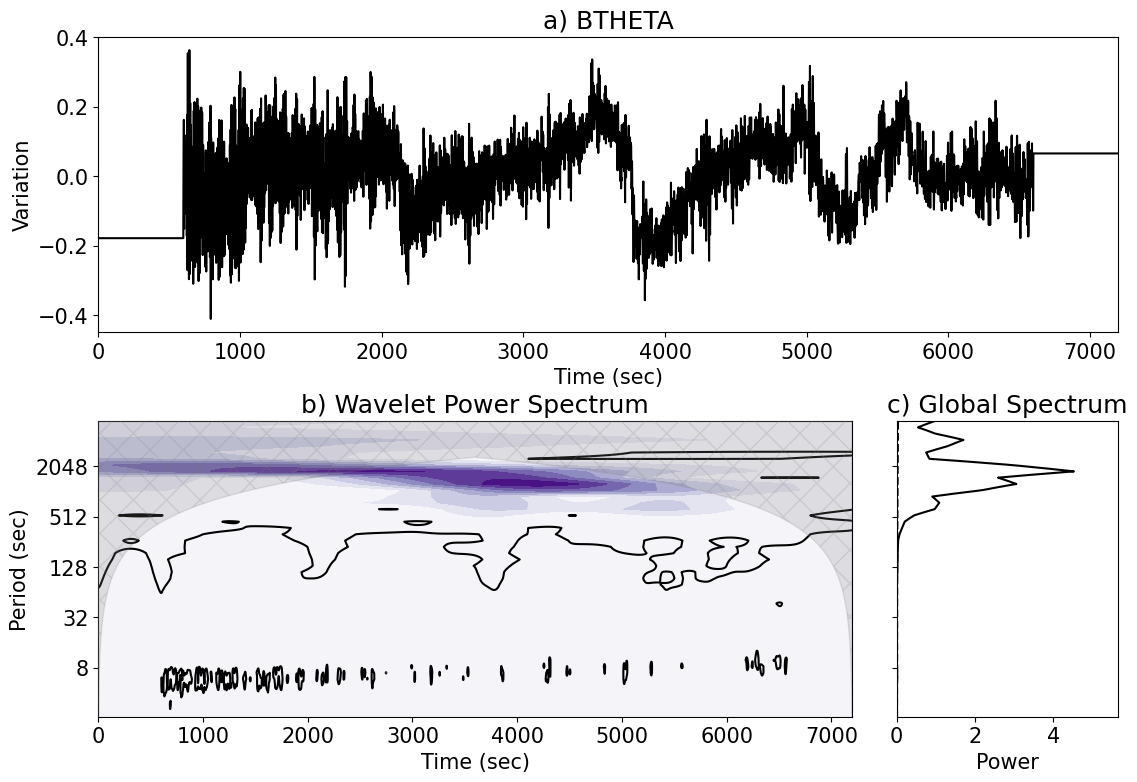

Data variance =  0.07530004919626784


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



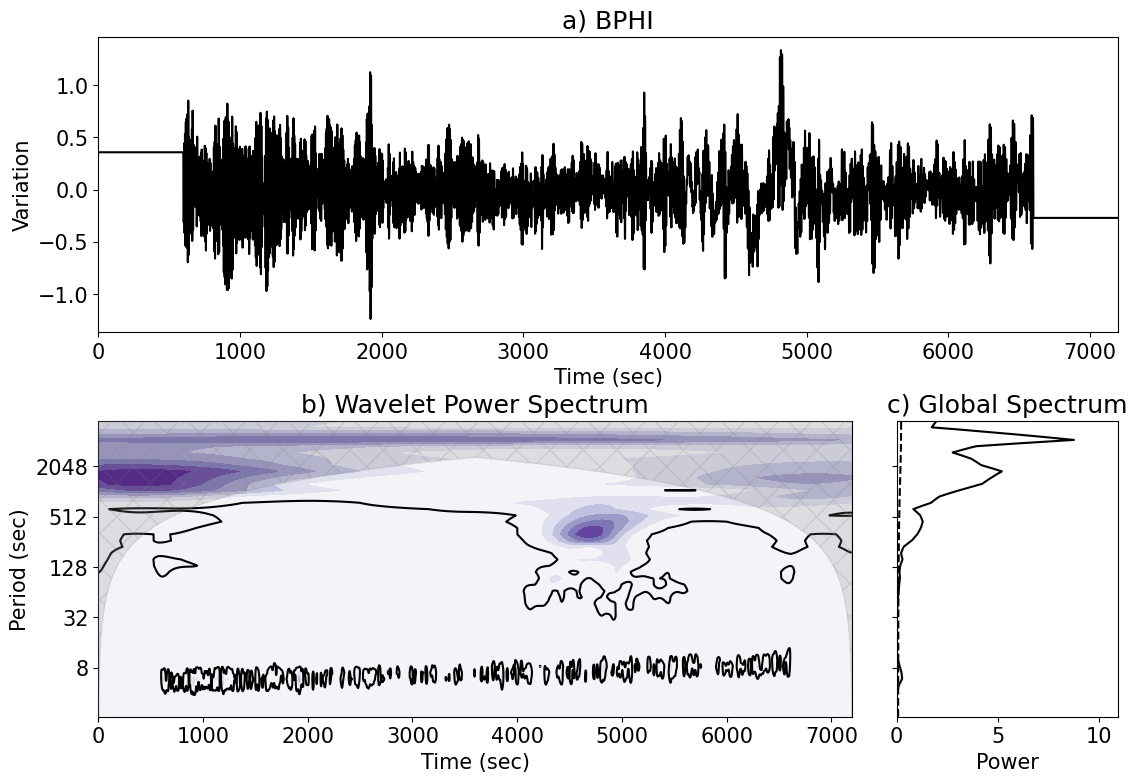

Data variance =  0.012619886991745172


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



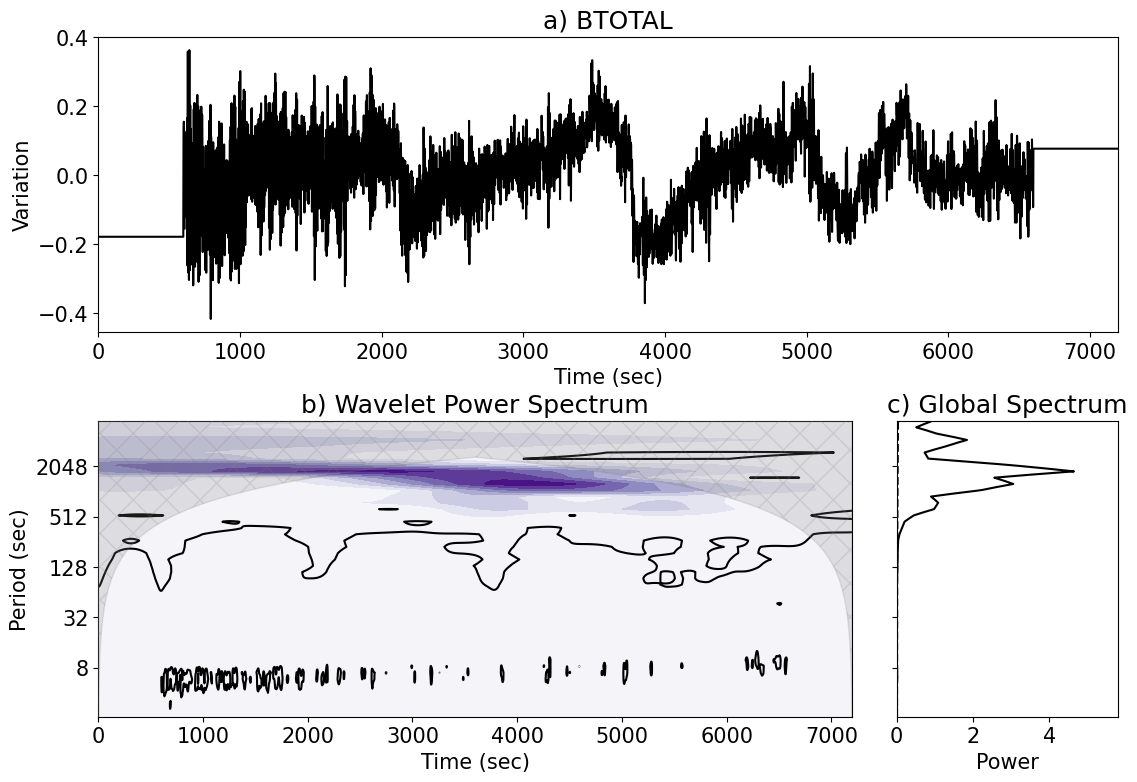

([np.float64(5.866087295498511),
  np.float64(157.26608729549864),
  np.float64(748.0660872954992),
  np.float64(1258.0660872954995),
  np.float64(1779.0660872955),
  np.float64(4231.266087295502)],
 array([   5.0660873,   99.4660873,  186.8660873,  889.4660873,
        1495.8660873, 2991.8660873]),
 array([   7.4660873,  186.8660873,  889.4660873, 1495.8660873,
        2991.8660873, 5984.0660873]))

In [105]:
start_time=pd.to_datetime('2010-12-21 02:00:00')
end_time=pd.to_datetime('2010-12-21 04:00:00')

df=select_df(start_time,end_time)
df=detrend_data(df)

do_wavelet(df['BR'].values,
           dt=1,unit='sec',title='BR')
do_wavelet(df['BTHETA'].values,
           dt=1,unit='sec',title='BTHETA')
do_wavelet(df['BPHI'].values,
           dt=1,unit='sec',title='BPHI')
do_wavelet(df['BTOTAL'].values,
           dt=1,unit='sec',title='BTOTAL')

Data variance =  1.1775801361369442


/Users/chengzhimao/Documents/Code/saturn2025/do_wavelet.py:188: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



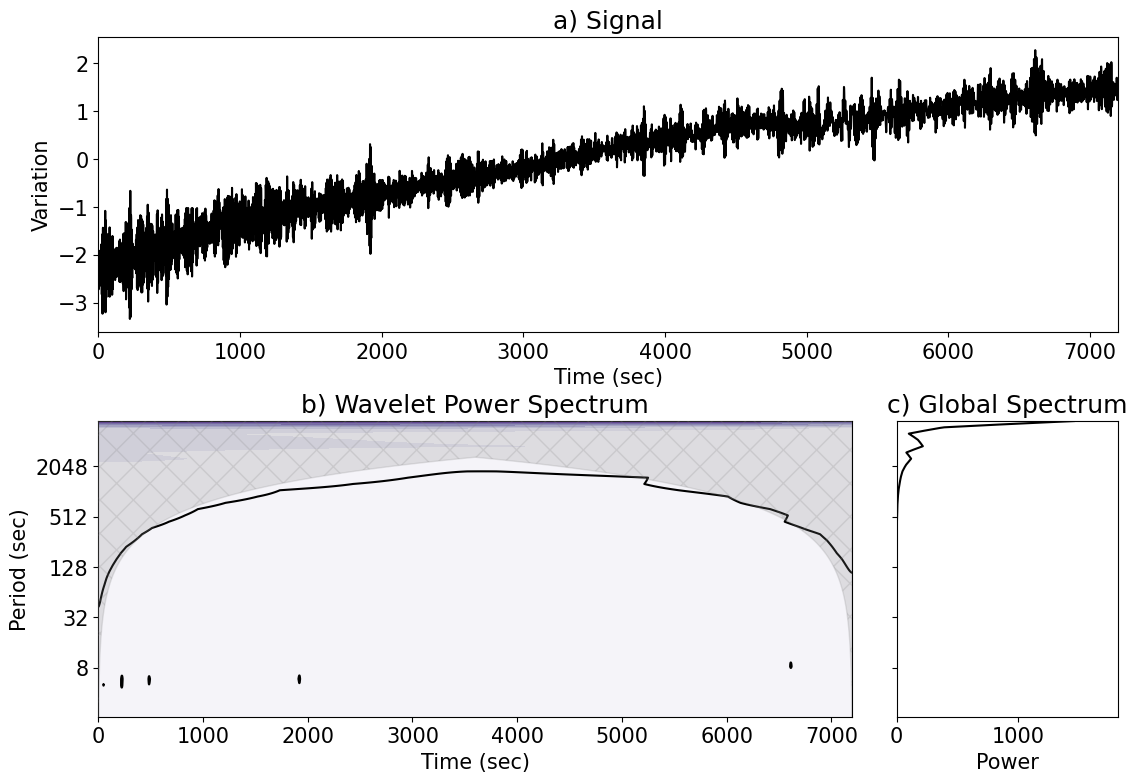

([np.float64(2516.066087295501), np.float64(3558.2660872955016)],
 array([ 358.4660873, 2991.8660873]),
 array([2991.8660873, 5031.8660873]))

In [80]:
start_time=pd.to_datetime('2010-12-21 02:00:00')
end_time=pd.to_datetime('2010-12-21 04:00:00')

df=select_df(start_time,end_time)
do_wavelet(df['BR'].values,dt=1,unit='sec')


In [84]:
1/(1.5*0.1)

6.666666666666666